# Alpha Engine — Exploration

Exploration of the data pulled by `eodhd_client`. Run on the shared `py313 (shared)` Jupyter kernel.

In [87]:
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import text

from alpha_engine.maintenance import archive_us_equities_tickers
from util.db import get_engine

In [88]:
# RUSSELL 3000- "IWV"
# S&P 500 - "SPY"
# NASDAQ 100 - "QQQ"

end_year = 2021

start_date = f"{end_year - 1}1201"
end_date = f"{end_year}1201"

with get_engine().connect() as conn:  # ~45M rows
    query = text(
        """
        SELECT symbol, exchange, date, [close], adjusted_close, volume
        FROM dbo.us_equities
        WHERE date >= :start_date
            AND date <  :end_date;
        """
    )
    df = pd.read_sql(
        query, conn, parse_dates=["date"], params={"start_date": start_date, "end_date": end_date}
    )

etf_df = df[df["symbol"].isin(["IWV", "SPY", "QQQ"])]
df = df[~df["symbol"].isin(["IWV", "SPY", "QQQ"])]

In [89]:
# wide_df = (
#     df.pivot(index="date", columns="symbol", values="adjusted_close")
#     .bfill(limit=1)
#     .ffill(limit_area="inside")
# )

# count_per_symbol = wide_df.count().reset_index(name="count")

# true_symbols = wide_df.columns[wide_df.count() >= count_per_symbol["count"].mode().iloc[0]]
# true_symbols_list = true_symbols.to_list()

# df = df.loc[df["symbol"].isin(true_symbols_list)]

## Exploratory Data Analysis

### 1. `#` of tickers per period

In [90]:
# import json
# from pathlib import Path

# ticker_counts_by_period: dict[str, int] = {}

# with get_engine().connect() as conn:
#     for end_year in range(2000, 2026):
#         start_date = f"{end_year - 1}1201"
#         end_date = f"{end_year}1201"

#         query = text(
#             """
#             SELECT COUNT(DISTINCT CONCAT(symbol, '|', exchange)) AS ticker_count
#             FROM dbo.us_equities
#             WHERE date >= :start_date
#               AND date < :end_date;
#             """
#         )

#         ticker_count = int(
#             pd.read_sql(
#                 query,
#                 conn,
#                 params={"start_date": start_date, "end_date": end_date},
#             ).iloc[0]["ticker_count"]
#         )
#         ticker_counts_by_period[f"{end_year}-12-01"] = ticker_count

# output_path = Path("ticker_counts_by_period.json")
# output_path.write_text(json.dumps(ticker_counts_by_period, indent=2), encoding="utf-8")

# ticker_counts_by_period

### 1a. Archive tickers with less than `365d` of history

In [91]:
print(
    f"Starting # of tickers for {end_year - 1}-12-01 until {end_year}-11-30:",
    len(df["symbol"].unique()),
)

Starting # of tickers for 2020-12-01 until 2021-11-30: 8960


In [92]:
# with get_engine().connect() as conn:
#     query = text(
#         """
#         SELECT symbol, exchange, start_date, end_date, delisted
#         FROM dbo.us_equities_ingest_status
#         """
#     )
#     tickers_df = pd.read_sql(query, conn, parse_dates=["start_date", "end_date"])

# tickers_subset_df = tickers_df.loc[
#     ((tickers_df["end_date"] - tickers_df["start_date"]).dt.days < 365)
#     & (tickers_df["end_date"].dt.date < datetime.date(2026, 8, 24))  # end_date - 10 days
# ]

# tickers_subset_df.loc[~tickers_subset_df["delisted"]]

# archive_us_equities_tickers(tickers_subset_df.loc[tickers_subset_df["delisted"]])

### 1b. Analyze the meaning of `_OLD` in ticker names

In [93]:
# with get_engine().connect() as conn:  # ~45M rows
#     query = text(
#         """
#         SELECT *
#         FROM dbo.us_equities_ingest_status
#         """
#     )
#     ticker_df = pd.read_sql(query, conn, parse_dates=["date"])

In [94]:
# ticker_sub1_df = ticker_df.loc[ticker_df["symbol"].str.contains("_OLD")]
# ticker_list = ticker_sub1_df["symbol"].str.replace("_OLD", "").tolist()
# ticker_sub2_df = ticker_df.loc[ticker_df["symbol"].isin(ticker_list)]

# ticker_sub_df = pd.concat([ticker_sub1_df, ticker_sub2_df], ignore_index=True).sort_values(
#     by="symbol"
# )

# e.g. ACH Accendra Health Inc v.s. ACH_OLD Aluminum Corp of China Ltd ADR
# Accendra Health, Inc. trades on the New York Stock Exchange under the new ticker symbol “ACH”,
# effective January 2, 2026.

### 2. Calculate historical `Dollar Volume` - `Russell 3000`
To make your strategy less susceptible to illiquidity traps, extreme volatility, and market manipulation, you need to define a minimum threshold for institutional market access. 

In [95]:
# ESSA - NASDAQ
df_sub = df[df["symbol"] == "ESSA"]

df_sub.head()

,symbol,exchange,date,close,adjusted_close,volume
604263,ESSA,NASDAQ,2020-12-01,15.52,13.6864,15790
604264,ESSA,NASDAQ,2020-12-02,15.51,13.6776,18777
604265,ESSA,NASDAQ,2020-12-03,15.66,13.8098,15060
604266,ESSA,NASDAQ,2020-12-04,16.07,14.1714,13030
604267,ESSA,NASDAQ,2020-12-07,15.81,13.9421,14582


In [96]:
df_sub["dollar_volume"] = df_sub["close"] * df_sub["volume"]

df_sub["dollar_volume"].describe()

count    2.580000e+02
mean     4.881713e+08
std      4.665964e+09
min      1.177200e+04
25%      1.260651e+05
50%      2.662758e+05
75%      4.439199e+05
max      5.795397e+10
Name: dollar_volume, dtype: float64

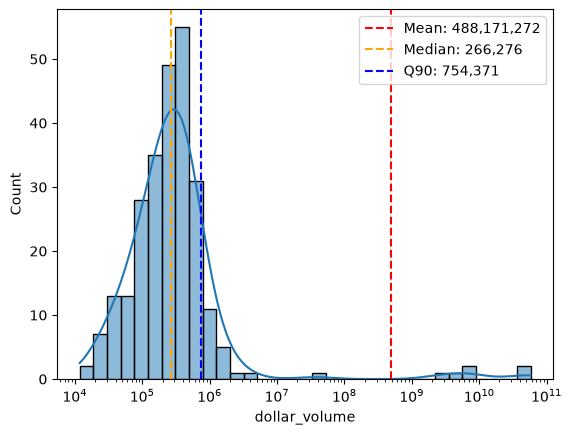

In [97]:
sns.histplot(data=df_sub, x="dollar_volume", log_scale=True, kde=True)

mean = df_sub["dollar_volume"].mean()
plt.axvline(mean, color="red", linestyle="--", label=f"Mean: {mean:,.0f}")

median = df_sub["dollar_volume"].median()
plt.axvline(median, color="orange", linestyle="--", label=f"Median: {median:,.0f}")

quant = df_sub["dollar_volume"].quantile(0.90)
plt.axvline(quant, color="blue", linestyle="--", label=f"Q90: {quant:,.0f}")

plt.legend()
plt.show()

In [98]:
# Regular Cases
df["dollar_volume"] = df["close"] * df["volume"]

df["dollar_volume"].describe()

count    1.913557e+06
mean     9.266097e+08
std      1.159642e+11
min      0.000000e+00
25%      1.158080e+05
50%      1.944923e+06
75%      1.944968e+07
max      3.869662e+13
Name: dollar_volume, dtype: float64

In [99]:
df["return"] = df.groupby(["symbol"])["adjusted_close"].pct_change()
symbol_std = df.groupby(["symbol"])["return"].agg(np.std).rename("volatility").reset_index()

std_threshold_list = symbol_std.loc[symbol_std["volatility"] >= 1]["symbol"].tolist()

<Axes: xlabel='volatility', ylabel='Count'>

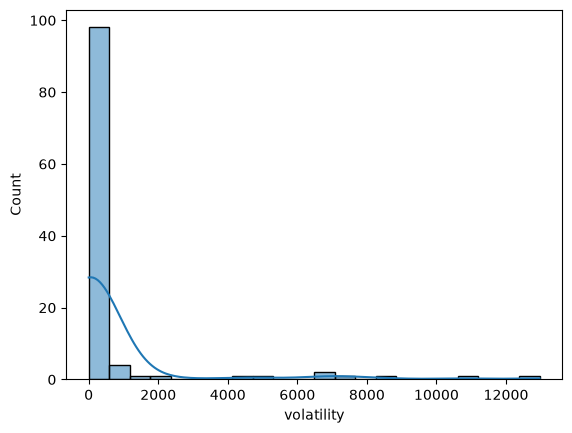

In [100]:
sns.histplot(data=symbol_std.loc[symbol_std["volatility"] > 1], x="volatility", kde=True)

<Axes: xlabel='volatility', ylabel='Count'>

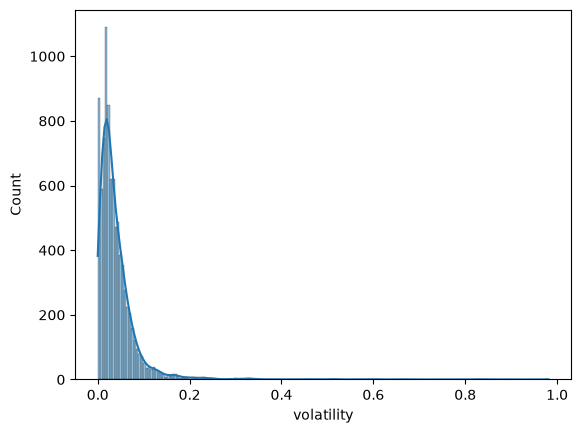

In [101]:
sns.histplot(data=symbol_std.loc[symbol_std["volatility"] <= 1], x="volatility", kde=True)

In [102]:
q90_volume = df.groupby("symbol")["dollar_volume"].quantile(q=0.90).reset_index()

avg_volume = df.groupby(["symbol"])["dollar_volume"].agg(np.nanmean).reset_index()
q90_threshold_list = q90_volume[q90_volume["dollar_volume"] < avg_volume["dollar_volume"]][
    "symbol"
].tolist()

c:\Users\lott7\.venvs\py313\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


<Axes: xlabel='dollar_volume', ylabel='Count'>

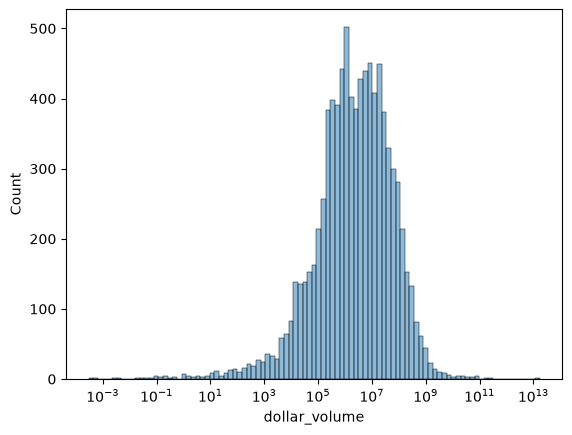

In [103]:
avg_day_volume = df.groupby(["symbol"])["dollar_volume"].agg(np.mean).reset_index()

sns.histplot(data=avg_day_volume, x="dollar_volume", log_scale=True, kde=True)

In [104]:
q = 1 - 2500 / len(avg_day_volume)
threshold = np.quantile(avg_day_volume["dollar_volume"], q)

print(f"Threshold to get the 2,500 stocks with the highes dollar_volume: ${threshold:,.2f}")

Threshold to get the 2,500 stocks with the highes dollar_volume: $15,560,856.95


<Axes: xlabel='dollar_volume', ylabel='Count'>

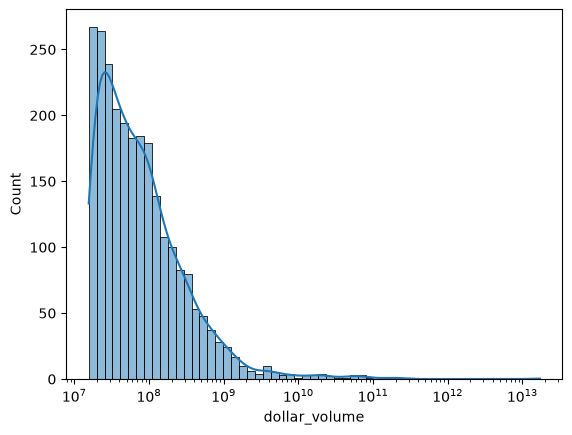

In [105]:
sns.histplot(
    data=avg_day_volume.loc[
        avg_day_volume["dollar_volume"] >= np.quantile(avg_day_volume["dollar_volume"], q=q)
    ],
    x="dollar_volume",
    log_scale=True,
    kde=True,
)

### 3. `Survivorship Bias` and its effects on selecting a complete training set
After analyzing the completeness of the data I thought about reducing the values of stocks per period to 2,000.

In [109]:
strategy_ticker_list = avg_day_volume.loc[
    avg_day_volume["dollar_volume"] >= np.quantile(avg_day_volume["dollar_volume"], q=q)
]["symbol"].tolist()

df = df[
    (df["symbol"].isin(strategy_ticker_list))
    & ~(df["symbol"].isin(std_threshold_list + q90_threshold_list))
]

wide_df = df.pivot(
    index="date", columns="symbol", values="adjusted_close"
)  # to be applied: .bfill(limit=5).ffill(limit_area="inside")

In [110]:
count_per_symbol = (
    wide_df.bfill(limit=5).ffill(limit_area="inside").count().reset_index(name="count")
)

count_per_symbol["count"].describe()

count    2437.000000
mean      241.886336
std        54.434990
min         3.000000
25%       260.000000
50%       260.000000
75%       260.000000
max       260.000000
Name: count, dtype: float64

In [111]:
count_per_symbol_subset = count_per_symbol.loc[
    count_per_symbol["count"] < count_per_symbol["count"].mode().iloc[0]
]

wide_df[count_per_symbol_subset.sort_values(by="count", ascending=False)["symbol"].tolist()].head()

symbol,CVA,AI,DASH,PUBM,ABNB,ABCL,CERT,OWL,SKLZ-WS,INOV_OLD2,...,MKULQ,GUG,LDG,TRNE,POW_OLD,BAM,TRNE-WS,DTG,TRNE-U,GMHI
date,,,,,,,,,,,,,,,,,,,,,
2020-12-01,12.4017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.92,...,NaN,NaN,6570.0,128.0,10100.0,NaN,12.80,NaN,12.80,17.00
2020-12-02,12.2351,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.61,...,NaN,NaN,6660.0,133.6,10800.0,NaN,13.36,NaN,13.36,18.00
2020-12-03,12.2841,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.40,...,NaN,NaN,6660.0,144.7,11400.0,NaN,14.47,NaN,14.47,22.98
2020-12-04,12.9502,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.56,...,NaN,NaN,6820.0,173.7,11550.0,NaN,17.37,NaN,17.37,NaN
2020-12-07,12.7053,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.50,...,NaN,NaN,6900.0,207.5,11450.0,NaN,20.75,NaN,20.75,NaN


In [112]:
wide_df[count_per_symbol_subset.sort_values(by="count", ascending=False)["symbol"].tolist()].head(
    15
)

symbol,CVA,AI,DASH,PUBM,ABNB,ABCL,CERT,OWL,SKLZ-WS,INOV_OLD2,...,MKULQ,GUG,LDG,TRNE,POW_OLD,BAM,TRNE-WS,DTG,TRNE-U,GMHI
date,,,,,,,,,,,,,,,,,,,,,
2020-12-01,12.4017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.92,...,NaN,NaN,6570.0,128.0,10100.0,NaN,12.80,NaN,12.80,17.00
2020-12-02,12.2351,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.61,...,NaN,NaN,6660.0,133.6,10800.0,NaN,13.36,NaN,13.36,18.00
2020-12-03,12.2841,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.40,...,NaN,NaN,6660.0,144.7,11400.0,NaN,14.47,NaN,14.47,22.98
2020-12-04,12.9502,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.56,...,NaN,NaN,6820.0,173.7,11550.0,NaN,17.37,NaN,17.37,NaN
2020-12-07,12.7053,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.50,...,NaN,NaN,6900.0,207.5,11450.0,NaN,20.75,NaN,20.75,NaN
2020-12-08,12.7739,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.74,...,NaN,NaN,6800.0,235.5,11350.0,NaN,23.55,NaN,23.55,NaN
2020-12-09,12.8817,92.49,189.51,29.45,NaN,NaN,NaN,NaN,NaN,19.34,...,NaN,NaN,6770.0,247.7,11400.0,NaN,24.77,NaN,24.77,NaN
2020-12-10,12.8621,130.00,186.00,27.35,144.71,NaN,NaN,NaN,NaN,19.70,...,NaN,NaN,6790.0,188.8,11300.0,NaN,NaN,NaN,NaN,NaN
2020-12-11,12.7641,119.58,175.00,25.05,139.25,58.90,38.08,NaN,NaN,19.42,...,NaN,NaN,6800.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<Axes: ylabel='Count'>

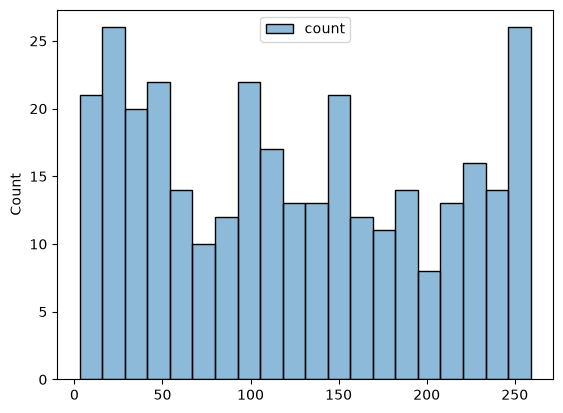

In [113]:
sns.histplot(
    count_per_symbol.loc[count_per_symbol["count"] < count_per_symbol["count"].mode().iloc[0]],
    bins=20,
)

# count_per_symbol.loc[
#     count_per_symbol["count"] < count_per_symbol["count"].mode().iloc[0]
# ].hist(bins=20)